# Практичне завдання 3: TF-IDF зважені ембедінги для детекції текстів, згенерованих LLM

**Датасет:** AI vs Human Text Classification Dataset 2026 (Kaggle, `alitaqishah/ai-vs-human-text-classification-dataset-2026`).

**Мета:** засвоїти побудову векторних представлень текстів на основі субсловних ембедінгів FastText, дослідити вплив TF-IDF зважування на агрегацію документних векторів, порівняти SVM, Logistic Regression і KNN у бінарній детекції штучних текстів та проаналізувати геометрію отриманих просторів.

**Гіпотеза (методичка):** TF-IDF зважування підсилює вплив рідкісних, специфічних для ШІ термінів і покращує лінійну роздільність порівняно з Mean Pooling.

**Експериментальний план:** метод агрегації (Mean Pooling / TF-IDF Weighted Mean) × класифікатор (SVM RBF / LogReg / KNN). Метрики: F1 (macro), Accuracy, Balanced Accuracy, ROC-AUC.

**Структура ноутбука** повторює методичку (Етапи 1–6 і дослідницькі питання).


## Імпорт бібліотек


In [1]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from gensim.models import FastText
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.metrics.pairwise import cosine_distances, euclidean_distances
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
np.random.seed(SEED)

CLASS_COLORS = {'human': '#4C72B0', 'ai': '#C44E52'}
DOMAIN_COLORS = {'academic': '#4C72B0', 'news': '#C44E52', 'social': '#55A868'}
DOMAIN_MARKERS = {'academic': 'o', 'news': 's', 'social': '^'}
AGGREGATIONS = ['Mean Pooling', 'TF-IDF Weighted']
CLASSIFIER_NAMES = ['SVM', 'LogReg', 'KNN']

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (8, 4.5)


## Етап 1. Завантаження та первинний аналіз даних

### 1.1. Структура датасету


In [2]:
raw = pd.read_csv('data/ai_vs_human_text_2026.csv')
print('Розмір датасету:', raw.shape)
raw.info()
raw.head()


Розмір датасету: (2000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   str    
 1   label                2000 non-null   str    
 2   source_model         2000 non-null   str    
 3   domain               2000 non-null   str    
 4   text_content         2000 non-null   str    
 5   topic_hint           2000 non-null   str    
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 140.8 KB


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


In [3]:
print('Баланс класів:')
print(pd.DataFrame({
    'count': raw['label'].value_counts(),
    'share_%': (raw['label'].value_counts(normalize=True) * 100).round(2),
}))
print()
display(pd.crosstab(raw['label'], raw['domain'], margins=True))
display(pd.crosstab(raw['label'], raw['source_model'], margins=True))
display(pd.crosstab(raw['label'], raw['generation_method'], margins=True))
print('Унікальних тем:', raw['topic_hint'].nunique())


Баланс класів:
       count  share_%
label                
human   1334     66.7
ai       666     33.3



domain,academic,news,social,All
label,,,,
ai,222,222,222,666
human,447,435,452,1334
All,669,657,674,2000


source_model,gemini-2.0,gpt-4o,human,All
label,,,,
ai,333,333,0,666
human,0,0,1334,1334
All,333,333,1334,2000


generation_method,style_simulation,template+human_variation,All
label,,,
ai,666,0,666
human,0,1334,1334
All,666,1334,2000


Унікальних тем: 30


### 1.2. Пошук артефактів: дублікати, порожні рядки, надмірно короткі тексти


In [4]:
SHORT_TEXT_WORDS = 5

normalized = raw['text_content'].str.strip().str.lower()
labels_per_text = raw.assign(norm=normalized).groupby('norm')['label'].nunique()

artifacts = pd.Series({
    'Рядків усього': len(raw),
    'Порожніх або NaN текстів': int(raw['text_content'].isna().sum() + (normalized == '').sum()),
    f'Текстів коротших за {SHORT_TEXT_WORDS} слів': int((raw['word_count'] < SHORT_TEXT_WORDS).sum()),
    'Точних дублікатів text_content': int(raw['text_content'].duplicated().sum()),
    'Дублікатів після нормалізації регістру': int(normalized.duplicated().sum()),
    'Унікальних нормалізованих текстів': int(normalized.nunique()),
    'Текстів з обома мітками одночасно': int((labels_per_text > 1).sum()),
})
display(artifacts.to_frame('значення'))

duplicates_by_label = raw.assign(is_dup=normalized.duplicated()).groupby('label')['is_dup'].agg(['sum', 'mean'])
duplicates_by_label.columns = ['дублікатів', 'частка']
display(duplicates_by_label.round(3))

print('Найчастіше повторювані тексти:')
display(raw['text_content'].value_counts().head(5).rename_axis('text').reset_index())


,значення
Рядків усього,2000
Порожніх або NaN текстів,0
Текстів коротших за 5 слів,0
Точних дублікатів text_content,1034
Дублікатів після нормалізації регістру,1058
Унікальних нормалізованих текстів,942
Текстів з обома мітками одночасно,0


,дублікатів,частка
label,,
ai,279,0.419
human,779,0.584


Найчастіше повторювані тексти:


,text,count
0,Recent scholarship on gig economy labor rights...,11
1,The theoretical underpinnings of autonomous ve...,9
2,A new study published today reveals that algor...,8
3,Recent scholarship on aging population challen...,7
4,The theoretical underpinnings of cryptocurrenc...,7


### 1.3. Видалення дублікатів до розбиття

Дублікати видаляємо **до** `train_test_split`. Інакше той самий текст опиниться і в train, і в test: KNN знаходитиме його як найближчого сусіда на нульовій відстані, а метрики вимірюватимуть запам'ятовування, а не узагальнення.


In [5]:
df = (
    raw.assign(norm=normalized)
    .drop_duplicates('norm')
    .drop(columns='norm')
    .reset_index(drop=True)
)
print('Після видалення дублікатів:', df.shape)
print(pd.DataFrame({
    'count': df['label'].value_counts(),
    'share_%': (df['label'].value_counts(normalize=True) * 100).round(2),
}))
display(pd.crosstab(df['label'], df['domain'], margins=True))
display(df.groupby('label')[['word_count', 'avg_sentence_length']].describe().T.round(2))


Після видалення дублікатів: (942, 9)
       count  share_%
label                
human    555    58.92
ai       387    41.08


domain,academic,news,social,All
label,,,,
ai,130,126,131,387
human,154,216,185,555
All,284,342,316,942


label                          ai   human
word_count          count  387.00  555.00
                    mean    37.93   36.03
                    std      7.03    9.40
                    min     23.00   19.00
                    25%     35.00   27.00
                    50%     39.00   36.00
                    75%     44.00   44.00
                    max     50.00   52.00
avg_sentence_length count  387.00  555.00
                    mean    13.28   12.11
                    std      2.23    3.09
                    min      8.70    6.50
                    25%     12.00    9.20
                    50%     13.00   12.00
                    75%     15.00   14.70
                    max     18.50   17.30

### 1.4. Шаблонна структура датасету

Стовпець `generation_method` натякає, що тексти побудовані за шаблонами (`template+human_variation`, `style_simulation`). Перевіряємо це: замінюємо в тексті тему `topic_hint` на заповнювач `<T>` і рахуємо, скільки різних каркасів лишається.


In [6]:
def extract_template(row: pd.Series) -> str:
    text = row['text_content'].strip().lower().replace(row['topic_hint'].lower(), '<T>')
    return ' '.join(text.split())


df['template'] = df.apply(extract_template, axis=1)
templates_by_class = df.groupby('template')['label'].nunique()

print('Документів:', len(df))
print('Різних шаблонів:', df['template'].nunique())
print('Тем:', df['topic_hint'].nunique())
print('Шаблонів за класами:', df.groupby('label')['template'].nunique().to_dict())
print('Шаблонів, що трапляються в обох класах:', int((templates_by_class > 1).sum()))
print('Шаблонів AI, що належать одній моделі-джерелу:',
      int((df[df['label'] == 'ai'].groupby('template')['source_model'].nunique() == 1).sum()))
print('Документів на шаблон:', df.groupby('template').size().describe().round(1).to_dict())

for label in ['human', 'ai']:
    print(f'\nНайчастіші шаблони класу {label}:')
    for template, count in df[df['label'] == label]['template'].value_counts().head(3).items():
        print(f'  [{count}] {template[:125]}...')


Документів: 942
Різних шаблонів: 38
Тем: 30
Шаблонів за класами: {'ai': 18, 'human': 20}
Шаблонів, що трапляються в обох класах: 0
Шаблонів AI, що належать одній моделі-джерелу: 18
Документів на шаблон: {'count': 38.0, 'mean': 24.8, 'std': 8.9, 'min': 12.0, '25%': 21.0, '50%': 23.0, '75%': 27.0, 'max': 51.0}

Найчастіші шаблони класу human:
  [51] the relationship between <T> and broader societal outcomes remains poorly understood despite growing interest in the field. t...
  [46] this paper examines <T> through a critical lens, drawing on empirical evidence gathered over a two-year period. the findings ...
  [45] a new study published today reveals that <T>. researchers from several universities collaborated on the findings, which have ...

Найчастіші шаблони класу ai:
  [26] i've been thinking a lot about <T> lately, and i think we need to have a more nuanced conversation about it. the polarization...
  [24] the concept of <T> occupies a contested space within contemporary scholarly 

### 1.5. Розподіл кількості слів


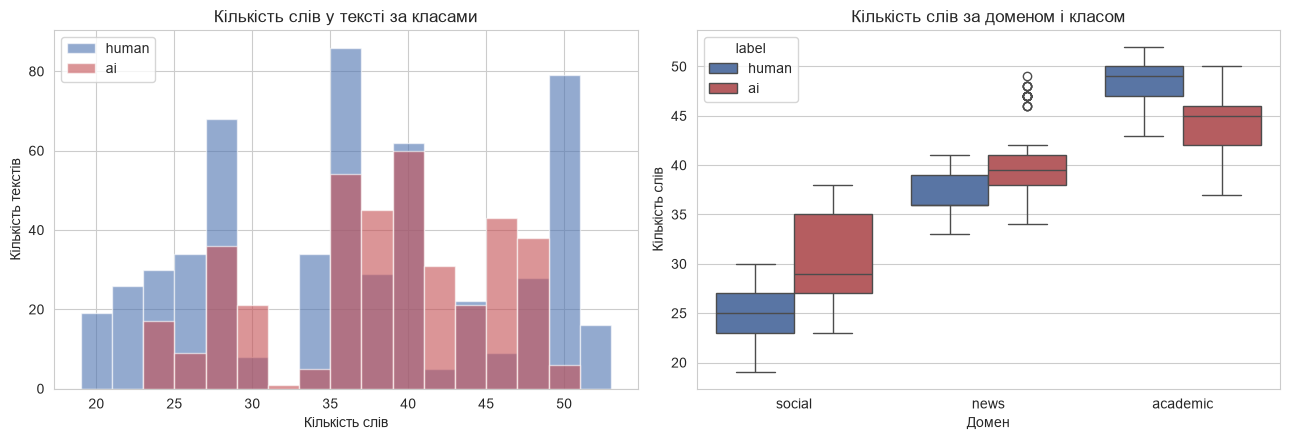

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.arange(df['word_count'].min(), df['word_count'].max() + 3, 2)
for label, color in CLASS_COLORS.items():
    axes[0].hist(
        df.loc[df['label'] == label, 'word_count'],
        bins=bins, alpha=0.6, color=color, edgecolor='white', label=label,
    )
axes[0].set_title('Кількість слів у тексті за класами')
axes[0].set_xlabel('Кількість слів')
axes[0].set_ylabel('Кількість текстів')
axes[0].legend()

sns.boxplot(
    data=df, x='domain', y='word_count', hue='label',
    palette=CLASS_COLORS, ax=axes[1],
)
axes[1].set_title('Кількість слів за доменом і класом')
axes[1].set_xlabel('Домен')
axes[1].set_ylabel('Кількість слів')
plt.tight_layout()
plt.show()


**Висновки первинного аналізу:**
- Датасет містить 2000 рядків без порожніх і надмірно коротких текстів, але лише 942 унікальні тексти. Після видалення 1058 дублікатів баланс змінився з 66.7/33.3 до 58.9/41.1 (Human/AI). Ще 75 документів мали ідентичний набір лем, тож у роботі лишилось **867 документів** із часткою AI 44.6%.
- Домени представлені приблизно порівну. Середня довжина класів близька (36.0 і 37.9 слова), а різниця змінює знак залежно від домену: у `social` і `news` тексти AI довші, в `academic` коротші. Тому довжина сама собою не є надійною ознакою класу.
- Гістограма має кілька виражених піків. Це прямий наслідок шаблонної структури.
- **Головна особливість:** весь датасет зводиться до **38 шаблонів і 30 тем**. Жоден шаблон не трапляється в обох класах, а кожен шаблон AI належить лише одній моделі-джерелу. Отже, знання шаблону повністю визначає клас, і це треба враховувати під час інтерпретації всіх наступних метрик.
- Назва `style_simulation` у стовпці `generation_method` вказує, що тексти класу AI могли бути не прямим виводом моделей, а імітацією їхнього стилю. Тому висновки про «маркери LLM» на цьому датасеті потрібно формулювати обережно.


## Етап 2. Попередня обробка тексту (spaCy)

Пайплайн згідно з методичкою: лематизація, видалення стоп-слів і небуквених токенів, нижній регістр. Для пришвидшення використано `nlp.pipe()` з батчами; компоненти `parser` і `ner` вимкнено, бо вони не потрібні для лем.

Після обробки частина різних рядків дає той самий список лем (наприклад, відрізняються лише числом чи пунктуацією). Для моделі це той самий документ із нульовою відстанню, тому такі дублікати теж видаляємо до поділу.


In [8]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])


def tokens_from_doc(doc: spacy.tokens.Doc) -> list[str]:
    return [token.lemma_.lower() for token in doc if token.is_alpha and not token.is_stop]


df['tokens'] = [
    tokens_from_doc(doc)
    for doc in nlp.pipe(df['text_content'].tolist(), batch_size=128)
]
df['n_tokens'] = df['tokens'].str.len()

token_duplicates = df['tokens'].map(tuple).duplicated()
print('Документів з ідентичним набором лем:', int(token_duplicates.sum()))
df = df[~token_duplicates].reset_index(drop=True)
print('Документів після видалення:', len(df), '| частка AI:', round((df['label'] == 'ai').mean(), 3))

print('\nТокенів на документ:')
print(df.groupby('label')['n_tokens'].describe().round(2))
print('\nДокументів без токенів:', int((df['n_tokens'] == 0).sum()))
for _, row in df.sample(2, random_state=SEED).iterrows():
    print(f"\n[{row['label']}] {row['text_content'][:140]}")
    print('->', row['tokens'][:18])


Документів з ідентичним набором лем: 75
Документів після видалення: 867 | частка AI: 0.446

Токенів на документ:
       count   mean   std   min   25%   50%   75%   max
label                                                  
ai     387.0  23.24  7.62  10.0  15.0  26.0  30.0  33.0
human  480.0  20.04  7.46   7.0  12.0  21.0  25.0  33.0

Документів без токенів: 0

[human] The theoretical underpinnings of vaccine distribution challenges have evolved considerably over the past two decades. What began as a niche 
-> ['theoretical', 'underpinning', 'vaccine', 'distribution', 'challenge', 'evolve', 'considerably', 'past', 'decade', 'begin', 'niche', 'area', 'inquiry', 'grow', 'robust', 'field', 'compete', 'school']

[human] update on renewable energy adoption: it's complicated and anyone telling you otherwise is selling something. do your own research please
-> ['update', 'renewable', 'energy', 'adoption', 'complicated', 'tell', 'sell', 'research']


## Етап 3. Розбиття вибірки та навчання FastText

Методичка розбиває вже готову матрицю `X`, але FastText і TF-IDF теж «навчаються» на даних. Якщо навчити їх на всьому корпусі, статистика тестових документів потрапить у представлення (data leakage). Тому спочатку ділимо дані зі стратифікацією 80/20, а FastText і `TfidfVectorizer` навчаємо **лише на train**.

Параметри FastText взяті з методички. Єдине відхилення: `workers=1` замість `workers=4`, бо багатопотокове навчання gensim не відтворюється навіть за фіксованого `seed`.


In [9]:
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=SEED
)
y_train = (train_df['label'] == 'ai').astype(int).to_numpy()
y_test = (test_df['label'] == 'ai').astype(int).to_numpy()
print(f'Train: {len(train_df)} | Test: {len(test_df)}')
print('Частка AI: train = %.3f, test = %.3f' % (y_train.mean(), y_test.mean()))


def train_fasttext(corpus: list[list[str]], seed: int = SEED) -> FastText:
    return FastText(
        sentences=corpus,
        vector_size=100,
        window=5,
        min_count=2,
        sg=1,
        workers=1,
        seed=seed,
    )


fasttext_model = train_fasttext(train_df['tokens'].tolist())
print('Розмір словника FastText:', len(fasttext_model.wv))


Train: 693 | Test: 174
Частка AI: train = 0.446, test = 0.448


Розмір словника FastText: 507


In [10]:
train_vocab = set(fasttext_model.wv.key_to_index)
test_tokens = [t for tokens in test_df['tokens'] for t in tokens]
oov_tokens = [t for t in test_tokens if t not in train_vocab]
print(f'OOV-токенів у test: {len(oov_tokens)} із {len(test_tokens)} ({len(oov_tokens) / len(test_tokens):.1%})')
print('Приклади OOV:', sorted(set(oov_tokens))[:10])

for word in ['study', 'research', 'policy']:
    print(word, '->', [(w, round(s, 3)) for w, s in fasttext_model.wv.most_similar(word, topn=5)])

oov_word = 'researchification'
print(f'\n{oov_word!r} у словнику: {oov_word in train_vocab}; вектор доступний через n-грами: {oov_word in fasttext_model.wv}')
print('Найближчі:', [w for w, _ in fasttext_model.wv.most_similar(oov_word, topn=5)])


OOV-токенів у test: 1 із 3882 (0.0%)
Приклади OOV: ['break']
study -> [('analyze', 0.96), ('dataset', 0.946), ('field', 0.935), ('analysis', 0.931), ('contribute', 0.929)]
research -> [('researcher', 0.982), ('unexpected', 0.927), ('collaborate', 0.921), ('university', 0.916), ('meet', 0.914)]
policy -> [('policymaker', 0.947), ('section', 0.91), ('consultation', 0.907), ('discuss', 0.906), ('jurisdiction', 0.905)]

'researchification' у словнику: False; вектор доступний через n-грами: True
Найближчі: ['coalition', 'sectional', 'jurisdiction', 'consultation', 'association']


## Етап 4. Векторизація документів

Обидві функції реалізують формули (5) і (6) методички. Вага токена — це його `tf · idf` у конкретному документі, а `idf` оцінюється лише на train.

У `TfidfVectorizer` формула idf інша: $\ln\frac{1+n}{1+df}+1$. Доданок $+1$ не дає часто вживаним словам нульову вагу, тому зважування виходить м'якшим, ніж за формулою (4). Для перевірки цього ефекту нижче є окремий варіант із чистим idf.


In [11]:
def mean_pooling(tokens: list[str], model: FastText) -> np.ndarray:
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)


def tfidf_weighted_pooling(
    tokens: list[str], model: FastText, tfidf_scores: dict[str, float]
) -> np.ndarray:
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors or sum(weights) == 0:
        return np.zeros(model.vector_size)
    return np.average(vectors, axis=0, weights=np.array(weights))


def identity(tokens: list[str]) -> list[str]:
    return tokens


def fit_tfidf(corpus: list[list[str]]) -> TfidfVectorizer:
    return TfidfVectorizer(
        analyzer='word', tokenizer=identity, preprocessor=identity,
        token_pattern=None, norm=None,
    ).fit(corpus)


def document_tfidf(tokens: list[str], idf_by_token: dict[str, float]) -> dict[str, float]:
    return {
        token: count * idf_by_token[token]
        for token, count in Counter(tokens).items()
        if token in idf_by_token
    }


def vectorize_mean(documents: pd.Series, model: FastText) -> np.ndarray:
    return np.vstack([mean_pooling(tokens, model) for tokens in documents])


def vectorize_tfidf(
    documents: pd.Series, model: FastText, idf_by_token: dict[str, float]
) -> np.ndarray:
    return np.vstack([
        tfidf_weighted_pooling(tokens, model, document_tfidf(tokens, idf_by_token))
        for tokens in documents
    ])


def fit_idf(corpus: list[list[str]], pure_log: bool = False) -> dict[str, float]:
    vectorizer = fit_tfidf(corpus)
    offset = 1.0 if pure_log else 0.0
    return {
        token: float(vectorizer.idf_[index] - offset)
        for token, index in vectorizer.vocabulary_.items()
    }


idf_train = fit_idf(train_df['tokens'].tolist())

X_train = {
    'Mean Pooling': vectorize_mean(train_df['tokens'], fasttext_model),
    'TF-IDF Weighted': vectorize_tfidf(train_df['tokens'], fasttext_model, idf_train),
}
X_test = {
    'Mean Pooling': vectorize_mean(test_df['tokens'], fasttext_model),
    'TF-IDF Weighted': vectorize_tfidf(test_df['tokens'], fasttext_model, idf_train),
}
for name, matrix in X_train.items():
    print(f'{name}: train {matrix.shape}, test {X_test[name].shape}')
print('Нульових векторів у test (TF-IDF):', int((np.abs(X_test['TF-IDF Weighted']).sum(axis=1) == 0).sum()))

idf_series = pd.Series(idf_train).sort_values()
print('\nНайменший idf:', idf_series.head(6).round(2).to_dict())
print('Найбільший idf:', idf_series.tail(4).round(2).to_dict())


Mean Pooling: train (693, 100), test (174, 100)
TF-IDF Weighted: train (693, 100), test (174, 100)
Нульових векторів у test (TF-IDF): 0

Найменший idf: {'challenge': 2.46, 'official': 2.76, 'study': 2.83, 'long': 2.88, 'come': 2.88, 'finding': 2.93}
Найбільший idf: {'hiring': 5.93, 'break': 6.85, 'data': 6.85, 'media': 6.85}


## Етап 5. Навчання та оцінка класифікаторів

Класифікатори налаштовані як у методичці. Перед кожним стоїть `StandardScaler`, навчений на train: компоненти усереднених FastText-векторів мають різний і малий масштаб, а це впливає і на RBF-ядро, і на регуляризацію LogReg, і на відстані в KNN.

Для порівняння додано наївний класифікатор, який завжди прогнозує найчастіший клас.


In [12]:
def make_classifiers(seed: int = SEED) -> dict:
    return {
        'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=seed)),
        'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=seed)),
        'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    }


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_score: np.ndarray) -> dict[str, float]:
    return {
        'F1_macro': f1_score(y_true, y_pred, average='macro'),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced_Acc': balanced_accuracy_score(y_true, y_pred),
        'ROC_AUC': roc_auc_score(y_true, y_score),
    }


rows = []
fitted = {}
for aggregation in AGGREGATIONS:
    for name, classifier in make_classifiers().items():
        classifier.fit(X_train[aggregation], y_train)
        fitted[(aggregation, name)] = classifier
        rows.append({
            'Агрегація': aggregation,
            'Класифікатор': name,
            **compute_metrics(
                y_test,
                classifier.predict(X_test[aggregation]),
                classifier.predict_proba(X_test[aggregation])[:, 1],
            ),
        })

baseline = DummyClassifier(strategy='most_frequent').fit(X_train['Mean Pooling'], y_train)
rows.append({
    'Агрегація': '—',
    'Класифікатор': 'Most frequent',
    **compute_metrics(
        y_test,
        baseline.predict(X_test['Mean Pooling']),
        baseline.predict_proba(X_test['Mean Pooling'])[:, 1],
    ),
})
holdout_results = pd.DataFrame(rows)
display(holdout_results.round(4))


,Агрегація,Класифікатор,F1_macro,Accuracy,Balanced_Acc,ROC_AUC
0,Mean Pooling,SVM,0.9942,0.9943,0.9948,0.9999
1,Mean Pooling,LogReg,1.0000,1.0000,1.0000,1.0000
2,Mean Pooling,KNN,1.0000,1.0000,1.0000,1.0000
3,TF-IDF Weighted,SVM,0.9942,0.9943,0.9948,0.9999
4,TF-IDF Weighted,LogReg,1.0000,1.0000,1.0000,1.0000
5,TF-IDF Weighted,KNN,1.0000,1.0000,1.0000,1.0000
6,—,Most frequent,0.3556,0.5517,0.5000,0.5000


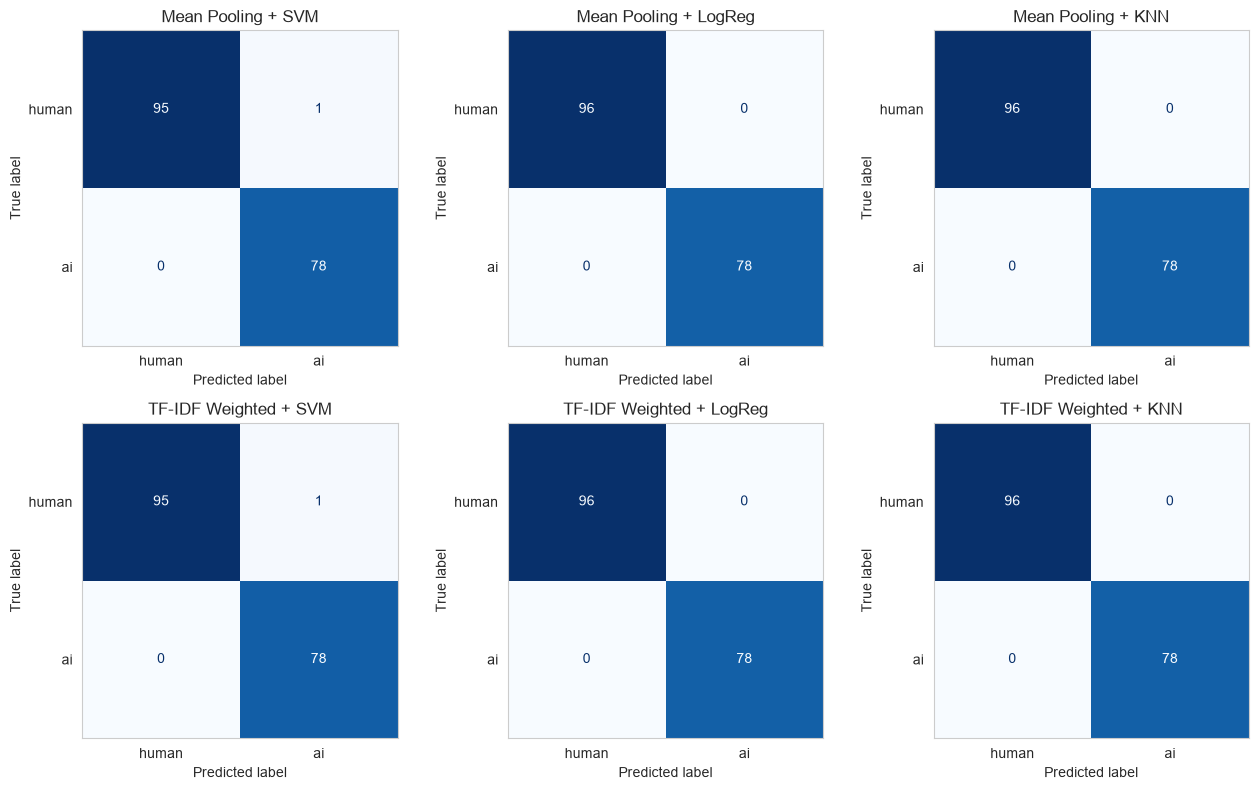

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row_index, aggregation in enumerate(AGGREGATIONS):
    for col_index, name in enumerate(CLASSIFIER_NAMES):
        ConfusionMatrixDisplay.from_estimator(
            fitted[(aggregation, name)], X_test[aggregation], y_test,
            display_labels=['human', 'ai'], cmap='Blues', colorbar=False,
            ax=axes[row_index, col_index],
        )
        axes[row_index, col_index].set_title(f'{aggregation} + {name}')
        axes[row_index, col_index].grid(False)
plt.tight_layout()
plt.show()


**Результати на тестовій вибірці.** Усі комбінації далеко випереджають наївний класифікатор (F1 = 0.356) і майже ідеальні: LogReg і KNN дають F1 = 1.000, SVM — 0.994 з однією помилкою. Методи агрегації дали **однакові** значення F1 для кожного класифікатора. Такий «ефект стелі» не дозволяє порівнювати підходи за одним поділом, тому далі виконуємо повторну крос-валідацію.


### 5.1. Перевірка стійкості: повторна крос-валідація

Тестова вибірка мала, тому один поділ дає шумну оцінку: одна помилка змінює accuracy приблизно на 0.5 п.п. Щоб не приймати випадковість за ефект агрегації, повторюємо весь пайплайн у `RepeatedStratifiedKFold` (5 блоків × 3 повторення). У кожному блоці FastText, idf і scaler навчаються заново лише на його train-частині.

Для різниць використовуємо скоригований t-тест Надо–Бенджіо: блоки перетинаються за train-даними, тому звичайний парний t-тест занижує дисперсію. Окремо оцінюємо варіант із чистим idf за формулою (4).


In [14]:
N_SPLITS = 5
N_REPEATS = 3


def corrected_ttest(differences: np.ndarray, test_to_train_ratio: float) -> tuple[float, float, float]:
    mean = float(np.mean(differences))
    variance = float(np.var(differences, ddof=1))
    n = len(differences)
    if variance == 0:
        return mean, 0.0, 1.0
    t_value = mean / np.sqrt(variance * (1 / n + test_to_train_ratio))
    p_value = 2 * stats.t.sf(abs(t_value), df=n - 1)
    return mean, float(t_value), float(p_value)


def evaluate_fold(train_part: pd.DataFrame, valid_part: pd.DataFrame, seed: int) -> list[dict]:
    y_tr = (train_part['label'] == 'ai').astype(int).to_numpy()
    y_va = (valid_part['label'] == 'ai').astype(int).to_numpy()
    model = train_fasttext(train_part['tokens'].tolist(), seed=seed)
    idf_soft = fit_idf(train_part['tokens'].tolist())
    idf_pure = fit_idf(train_part['tokens'].tolist(), pure_log=True)
    representations = {
        'Mean Pooling': (
            vectorize_mean(train_part['tokens'], model),
            vectorize_mean(valid_part['tokens'], model),
        ),
        'TF-IDF Weighted': (
            vectorize_tfidf(train_part['tokens'], model, idf_soft),
            vectorize_tfidf(valid_part['tokens'], model, idf_soft),
        ),
        'TF-IDF (idf без +1)': (
            vectorize_tfidf(train_part['tokens'], model, idf_pure),
            vectorize_tfidf(valid_part['tokens'], model, idf_pure),
        ),
    }
    fold_rows = []
    for aggregation, (X_tr, X_va) in representations.items():
        for name, classifier in make_classifiers(seed).items():
            classifier.fit(X_tr, y_tr)
            fold_rows.append({
                'aggregation': aggregation,
                'classifier': name,
                **compute_metrics(y_va, classifier.predict(X_va), classifier.predict_proba(X_va)[:, 1]),
            })
    return fold_rows


cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
cv_rows = []
for fold_id, (train_idx, valid_idx) in enumerate(cv.split(train_df, y_train)):
    for row in evaluate_fold(train_df.iloc[train_idx], train_df.iloc[valid_idx], SEED + fold_id):
        cv_rows.append({'fold': fold_id, **row})
cv_results = pd.DataFrame(cv_rows)

cv_summary = cv_results.groupby(['aggregation', 'classifier'])[
    ['F1_macro', 'Accuracy', 'Balanced_Acc', 'ROC_AUC']
].agg(lambda s: f'{s.mean():.4f} ± {s.std():.4f}')
display(cv_summary)


F1_macro         Accuracy  \
aggregation         classifier                                     
Mean Pooling        KNN         0.9985 ± 0.0030  0.9986 ± 0.0030   
                    LogReg      0.9844 ± 0.0126  0.9846 ± 0.0124   
                    SVM         0.9899 ± 0.0191  0.9899 ± 0.0190   
TF-IDF (idf без +1) KNN         0.9995 ± 0.0019  0.9995 ± 0.0019   
                    LogReg      0.9883 ± 0.0109  0.9885 ± 0.0108   
                    SVM         0.9879 ± 0.0202  0.9880 ± 0.0202   
TF-IDF Weighted     KNN         0.9990 ± 0.0026  0.9990 ± 0.0025   
                    LogReg      0.9869 ± 0.0114  0.9870 ± 0.0113   
                    SVM         0.9879 ± 0.0202  0.9880 ± 0.0202   

                                   Balanced_Acc          ROC_AUC  
aggregation         classifier                                    
Mean Pooling        KNN         0.9987 ± 0.0027  1.0000 ± 0.0000  
                    LogReg      0.9846 ± 0.0128  0.9986 ± 0.0024  
                    SVM         0.9909 ± 0.0172  0.9995 ± 0.0016  
TF-IDF (idf без +1) KNN         0.9996 ± 0.0017  1.0000 ± 0.0000  
                    LogReg      0.9886 ± 0.0105  0.9986 ± 0.0025  
                    SVM         0.9890 ± 0.0183  0.9995 ± 0.0016  
TF-IDF Weighted     KNN         0.9991 ± 0.0023  1.0000 ± 0.0000  
                    LogReg      0.9871 ± 0.0111  0.9986 ± 0.0024  
                    SVM         0.9891 ± 0.0182  0.9995 ± 0.0015

In [15]:
TEST_TO_TRAIN = 1 / (N_SPLITS - 1)
ALPHA = 0.05

ttest_rows = []
for candidate in ['TF-IDF Weighted', 'TF-IDF (idf без +1)']:
    for name in CLASSIFIER_NAMES:
        for metric in ['F1_macro', 'ROC_AUC']:
            pivot = cv_results[cv_results['classifier'] == name].pivot(
                index='fold', columns='aggregation', values=metric
            )
            mean_diff, t_value, p_value = corrected_ttest(
                (pivot[candidate] - pivot['Mean Pooling']).to_numpy(), TEST_TO_TRAIN
            )
            ttest_rows.append({
                'Порівняння': f'{candidate} − Mean',
                'Класифікатор': name,
                'Метрика': metric,
                'd̄': round(mean_diff, 4),
                't': round(t_value, 3),
                'p': round(p_value, 4),
                'Значуще': p_value < ALPHA,
            })
ttest_table = pd.DataFrame(ttest_rows)
display(ttest_table)


,Порівняння,Класифікатор,Метрика,d̄,t,p,Значуще
0,TF-IDF Weighted − Mean,SVM,F1_macro,-0.0019,-1.035,0.3181,False
1,TF-IDF Weighted − Mean,SVM,ROC_AUC,0.0000,0.459,0.6534,False
2,TF-IDF Weighted − Mean,LogReg,F1_macro,0.0024,0.819,0.4267,False
3,TF-IDF Weighted − Mean,LogReg,ROC_AUC,0.0001,0.336,0.7416,False
4,TF-IDF Weighted − Mean,KNN,F1_macro,0.0005,0.459,0.6534,False
5,TF-IDF Weighted − Mean,KNN,ROC_AUC,0.0000,0.000,1.0000,False
6,TF-IDF (idf без +1) − Mean,SVM,F1_macro,-0.0019,-1.035,0.3181,False
7,TF-IDF (idf без +1) − Mean,SVM,ROC_AUC,-0.0000,-0.367,0.7192,False
8,TF-IDF (idf без +1) − Mean,LogReg,F1_macro,0.0039,1.137,0.2747,False
9,TF-IDF (idf без +1) − Mean,LogReg,ROC_AUC,0.0000,0.161,0.8744,False


**Результат.** Зі стійкою оцінкою картина та сама: F1 перебуває в межах 0.984–0.999 для всіх комбінацій. Різниця між TF-IDF і Mean Pooling не перевищує 0.4 п.п. і є **статистично незначущою** в усіх 12 порівняннях (найменше p = 0.27). Варіант із чистим idf також нічого не змінює.

KNN виявився найкращим (F1 ≈ 0.999), що для метричного методу в 100-вимірному просторі незвично. Причину пояснює наступний експеримент.


### 5.2. Узагальнення на нові шаблони

Випадковий поділ кладе той самий шаблон і в train, і в test, тому навіть ідеальна оцінка може означати лише впізнавання шаблону. Реальний детектор зустрічатиме тексти, яких не бачив у такій формі. Перевіряємо це за допомогою `StratifiedGroupKFold` з групою `template`: шаблони валідаційного блоку повністю відсутні під час навчання FastText, idf, scaler і класифікатора.

Це додатковий експеримент понад методичку. Весь пайплайн той самий, змінюється лише спосіб поділу.


In [16]:
from sklearn.model_selection import StratifiedGroupKFold

GROUP_REPEATS = 3
groups_train = train_df['template'].to_numpy()
all_groups = df['template'].to_numpy()
all_labels = (df['label'] == 'ai').astype(int).to_numpy()

group_rows = []
oov_shares = []
fold_id = 0
for repeat in range(GROUP_REPEATS):
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + repeat)
    for train_idx, valid_idx in splitter.split(df, all_labels, groups=all_groups):
        train_part, valid_part = df.iloc[train_idx], df.iloc[valid_idx]
        assert not set(train_part['template']) & set(valid_part['template'])
        known = {t for tokens in train_part['tokens'] for t in tokens}
        valid_tokens = [t for tokens in valid_part['tokens'] for t in tokens]
        oov_shares.append(np.mean([t not in known for t in valid_tokens]))
        for row in evaluate_fold(train_part, valid_part, SEED + fold_id):
            group_rows.append({'fold': fold_id, **row})
        fold_id += 1
group_results = pd.DataFrame(group_rows)

print(f'Частка OOV-токенів у валідаційних блоках: {np.mean(oov_shares):.1%}')
group_summary = group_results.groupby(['aggregation', 'classifier'])[
    ['F1_macro', 'Accuracy', 'Balanced_Acc', 'ROC_AUC']
].agg(lambda s: f'{s.mean():.4f} ± {s.std():.4f}')
display(group_summary)

group_ttests = []
for candidate in ['TF-IDF Weighted', 'TF-IDF (idf без +1)']:
    for name in CLASSIFIER_NAMES:
        for metric in ['F1_macro', 'ROC_AUC']:
            pivot = group_results[group_results['classifier'] == name].pivot(
                index='fold', columns='aggregation', values=metric
            )
            mean_diff, t_value, p_value = corrected_ttest(
                (pivot[candidate] - pivot['Mean Pooling']).to_numpy(), TEST_TO_TRAIN
            )
            group_ttests.append({
                'Порівняння': f'{candidate} − Mean',
                'Класифікатор': name,
                'Метрика': metric,
                'd̄': round(mean_diff, 4),
                't': round(t_value, 3),
                'p': round(p_value, 4),
                'Значуще': p_value < ALPHA,
            })
display(pd.DataFrame(group_ttests))


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Частка OOV-токенів у валідаційних блоках: 41.2%


F1_macro         Accuracy  \
aggregation         classifier                                     
Mean Pooling        KNN         0.4435 ± 0.1110  0.5087 ± 0.1060   
                    LogReg      0.4628 ± 0.0588  0.5317 ± 0.0402   
                    SVM         0.4594 ± 0.0665  0.5271 ± 0.0513   
TF-IDF (idf без +1) KNN         0.4512 ± 0.1051  0.4859 ± 0.1005   
                    LogReg      0.4774 ± 0.1297  0.4889 ± 0.1298   
                    SVM         0.5061 ± 0.1062  0.5512 ± 0.0882   
TF-IDF Weighted     KNN         0.4449 ± 0.0978  0.4790 ± 0.0929   
                    LogReg      0.4738 ± 0.1245  0.4854 ± 0.1250   
                    SVM         0.5043 ± 0.1038  0.5497 ± 0.0850   

                                   Balanced_Acc          ROC_AUC  
aggregation         classifier                                    
Mean Pooling        KNN         0.5429 ± 0.1073  0.5138 ± 0.1443  
                    LogReg      0.5767 ± 0.0295  0.3847 ± 0.1483  
                    SVM         0.5718 ± 0.0365  0.5515 ± 0.2161  
TF-IDF (idf без +1) KNN         0.5136 ± 0.1076  0.5125 ± 0.1289  
                    LogReg      0.5109 ± 0.1335  0.4421 ± 0.1318  
                    SVM         0.5909 ± 0.0769  0.5154 ± 0.1663  
TF-IDF Weighted     KNN         0.5078 ± 0.1016  0.5099 ± 0.1182  
                    LogReg      0.5075 ± 0.1289  0.4342 ± 0.1343  
                    SVM         0.5893 ± 0.0729  0.5095 ± 0.1663

,Порівняння,Класифікатор,Метрика,d̄,t,p,Значуще
0,TF-IDF Weighted − Mean,SVM,F1_macro,0.0449,0.926,0.3703,False
1,TF-IDF Weighted − Mean,SVM,ROC_AUC,-0.0420,-0.797,0.4385,False
2,TF-IDF Weighted − Mean,LogReg,F1_macro,0.0110,0.158,0.8769,False
3,TF-IDF Weighted − Mean,LogReg,ROC_AUC,0.0495,0.405,0.6913,False
4,TF-IDF Weighted − Mean,KNN,F1_macro,0.0014,0.033,0.9742,False
5,TF-IDF Weighted − Mean,KNN,ROC_AUC,-0.0039,-0.080,0.9372,False
6,TF-IDF (idf без +1) − Mean,SVM,F1_macro,0.0468,0.943,0.3619,False
7,TF-IDF (idf без +1) − Mean,SVM,ROC_AUC,-0.0361,-0.682,0.5067,False
8,TF-IDF (idf без +1) − Mean,LogReg,F1_macro,0.0147,0.202,0.8425,False
9,TF-IDF (idf без +1) − Mean,LogReg,ROC_AUC,0.0574,0.473,0.6434,False


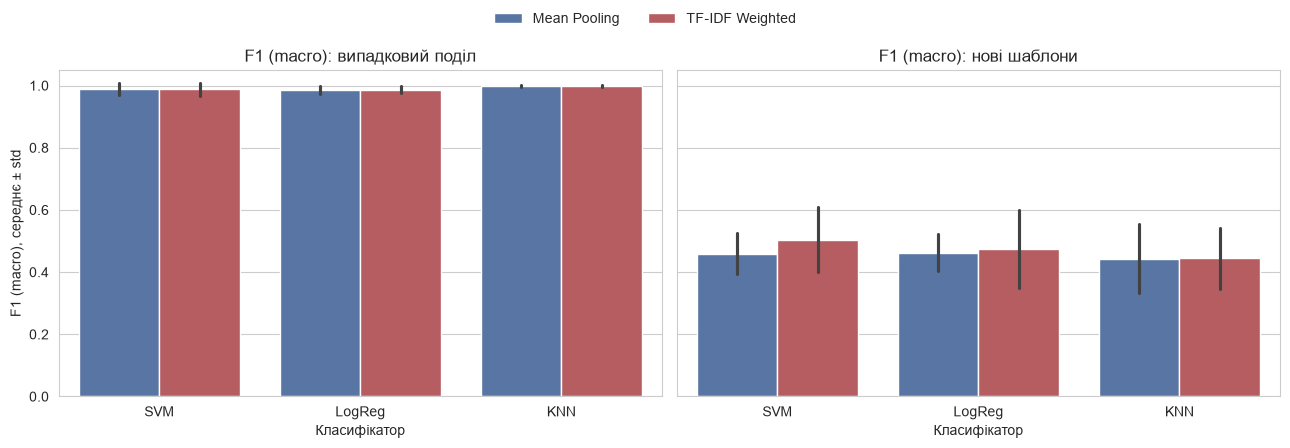

In [17]:
comparison = pd.concat([
    cv_results.assign(split='Випадковий поділ'),
    group_results.assign(split='Нові шаблони'),
])
comparison = comparison[comparison['aggregation'].isin(AGGREGATIONS)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axis, split_name in zip(axes, ['Випадковий поділ', 'Нові шаблони']):
    sns.barplot(
        data=comparison[comparison['split'] == split_name],
        x='classifier', y='F1_macro', hue='aggregation', order=CLASSIFIER_NAMES,
        palette=['#4C72B0', '#C44E52'], errorbar='sd', ax=axis,
    )
    axis.set_title(f'F1 (macro): {split_name.lower()}')
    axis.set_xlabel('Класифікатор')
    axis.set_ylabel('F1 (macro), середнє ± std')
    axis.set_ylim(0, 1.05)
    axis.get_legend().remove()
handles, legend_labels = axes[1].get_legend_handles_labels()
plt.tight_layout(rect=(0, 0, 1, 0.93))
fig.legend(handles, legend_labels, loc='upper center', ncol=2, frameon=False)
plt.show()


**Результат: при нових шаблонах якість падає до рівня випадкового вгадування.**

| Класифікатор | F1, випадковий поділ (Mean / TF-IDF) | F1, нові шаблони (Mean / TF-IDF) | ROC-AUC, нові шаблони (Mean / TF-IDF) |
|---|---|---|---|
| SVM | 0.990 / 0.988 | 0.459 / 0.504 | 0.552 / 0.510 |
| LogReg | 0.984 / 0.987 | 0.463 / 0.474 | 0.385 / 0.434 |
| KNN | 0.999 / 0.999 | 0.444 / 0.445 | 0.514 / 0.510 |

Майже ідеальні результати випадкового поділу пояснюються **впізнаванням шаблону**, а не виявленням ознак штучного тексту. ROC-AUC близько 0.5, а для LogReg навіть нижче, тому між шаблонами немає стійкого напряму, який відділяв би AI від Human.

TF-IDF дає трохи вищий середній F1 для SVM (+0.045), проте при стандартному відхиленні близько 0.1 різниця незначуща (p = 0.37), а ROC-AUC у цього ж класифікатора нижчий. Частка OOV-токенів становить 41.2%, тож тут реально перевіряється перевага FastText для невідомих слів, але цього недостатньо для узагальнення.

**Обмеження:** шаблонів лише 38, тому кожен блок містить кілька шаблонів, і оцінка має велику дисперсію. Результат не доводить, що детекція неможлива загалом. Він показує, що цей датасет не дає підстав стверджувати про її успішність.


### 5.3. Якість за доменами та джерелами

Ці зрізи показують, де саме модель помиляється. Цільова мітка й `source_model` не використовуються як ознаки, а лише для аналізу результату на test.


In [18]:
slice_rows = []
for aggregation in AGGREGATIONS:
    for name in ['SVM', 'LogReg']:
        predictions = fitted[(aggregation, name)].predict(X_test[aggregation])
        for domain in sorted(test_df['domain'].unique()):
            mask = (test_df['domain'] == domain).to_numpy()
            slice_rows.append({
                'Агрегація': aggregation, 'Класифікатор': name, 'Зріз': domain,
                'n': int(mask.sum()),
                'F1_macro': f1_score(y_test[mask], predictions[mask], average='macro'),
            })
        for source in ['gemini-2.0', 'gpt-4o']:
            mask = (test_df['source_model'] == source).to_numpy()
            slice_rows.append({
                'Агрегація': aggregation, 'Класифікатор': name, 'Зріз': f'recall {source}',
                'n': int(mask.sum()),
                'F1_macro': float(predictions[mask].mean()),
            })
slice_table = pd.DataFrame(slice_rows).pivot_table(
    index=['Зріз', 'n'], columns=['Агрегація', 'Класифікатор'], values='F1_macro'
).round(3)
display(slice_table)


Агрегація            Mean Pooling        TF-IDF Weighted       
Класифікатор               LogReg    SVM          LogReg    SVM
Зріз              n                                            
academic          57          1.0  1.000             1.0  1.000
news              59          1.0  1.000             1.0  1.000
recall gemini-2.0 38          1.0  1.000             1.0  1.000
recall gpt-4o     40          1.0  1.000             1.0  1.000
social            58          1.0  0.981             1.0  0.981

## Етап 6. Візуалізація та аналіз

### 6.1. Проєкція t-SNE

t-SNE застосовано до всіх документів (вектори побудовані моделями, навченими на train). Це лише візуалізація, у навчанні класифікаторів вона не бере участі. Кожен метод показано двічі: за класом і за доменом, щоб побачити, що саме структурує простір.


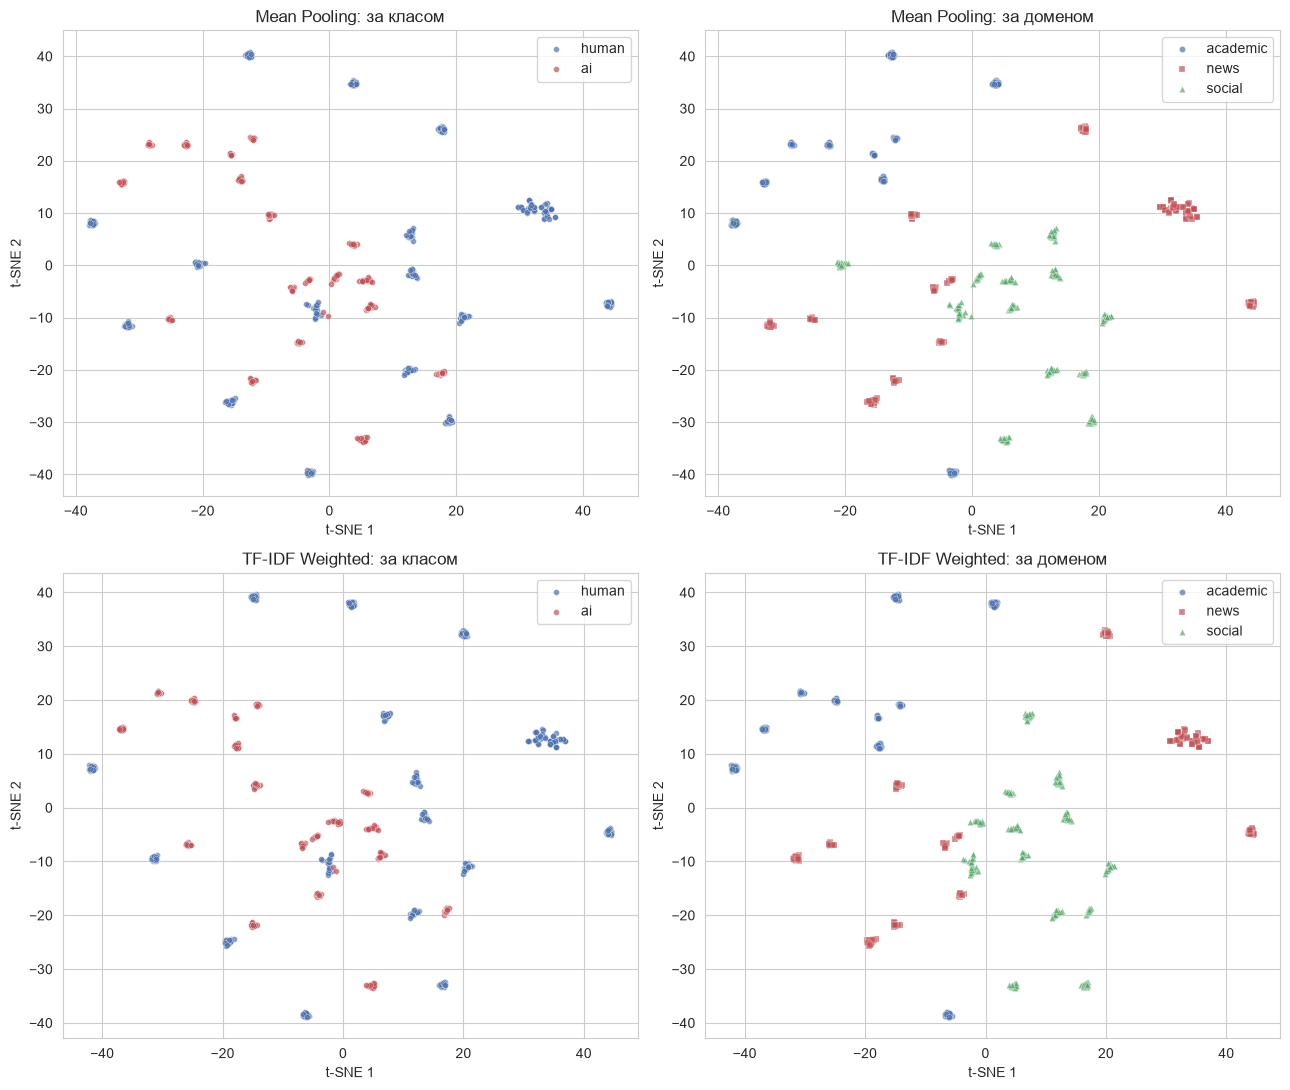

In [19]:
all_df = pd.concat([train_df, test_df], ignore_index=True)
X_all = {
    aggregation: np.vstack([X_train[aggregation], X_test[aggregation]])
    for aggregation in AGGREGATIONS
}
projections = {
    aggregation: TSNE(
        n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED
    ).fit_transform(StandardScaler().fit_transform(X_all[aggregation]))
    for aggregation in AGGREGATIONS
}

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row_index, aggregation in enumerate(AGGREGATIONS):
    points = projections[aggregation]
    for label, color in CLASS_COLORS.items():
        mask = (all_df['label'] == label).to_numpy()
        axes[row_index, 0].scatter(
            points[mask, 0], points[mask, 1], s=18, c=color, alpha=0.7,
            edgecolors='white', linewidths=0.3, label=label,
        )
    axes[row_index, 0].set_title(f'{aggregation}: за класом')
    axes[row_index, 0].legend()
    for domain, color in DOMAIN_COLORS.items():
        mask = (all_df['domain'] == domain).to_numpy()
        axes[row_index, 1].scatter(
            points[mask, 0], points[mask, 1], s=20, c=color, alpha=0.7,
            marker=DOMAIN_MARKERS[domain], edgecolors='white', linewidths=0.3, label=domain,
        )
    axes[row_index, 1].set_title(f'{aggregation}: за доменом')
    axes[row_index, 1].legend()
    for axis in axes[row_index]:
        axis.set_xlabel('t-SNE 1')
        axis.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()


**Спостереження.** Обидва методи дають майже однакову картину з окремих компактних «острівців». Кольори не змішуються всередині острівців, але острівці AI та Human перемежовуються: єдиної межі чи двох великих кластерів немає. Правий стовпець показує, що острівці групуються за доменом. Отже, простір структурований ієрархічно: шаблон → домен, а клас не утворює власної структури.


### 6.2. Кількісний аналіз геометрії простору

t-SNE спотворює глобальні відстані, тому висновки перевіряємо у вихідному 100-вимірному просторі. Метрики:
- **silhouette** за класом, доменом і шаблоном (косинусна відстань);
- середня довжина вектора та дисперсія між документами;
- **відносний контраст** $(d_{max}-d_{min})/d_{min}$: чим він менший, тим слабше відрізняються близькі й далекі сусіди (прояв «прокляття розмірності»);
- **чистота сусідів**: частка з 5 найближчих сусідів, що мають той самий клас;
- кількість компонент PCA, які пояснюють 90% дисперсії.


In [20]:
from sklearn.decomposition import PCA


def neighbor_purity(matrix: np.ndarray, labels: np.ndarray, k: int = 5) -> float:
    distances = euclidean_distances(matrix)
    np.fill_diagonal(distances, np.inf)
    neighbors = np.argsort(distances, axis=1)[:, :k]
    return float((labels[neighbors] == labels[:, None]).mean())


def relative_contrast(matrix: np.ndarray) -> float:
    distances = euclidean_distances(matrix)
    np.fill_diagonal(distances, np.nan)
    nearest = np.nanmin(distances, axis=1)
    farthest = np.nanmax(distances, axis=1)
    return float(np.mean((farthest - nearest) / nearest))


def within_between_distance(matrix: np.ndarray, labels: np.ndarray) -> tuple[float, float]:
    distances = cosine_distances(matrix)
    same = labels[:, None] == labels[None, :]
    off_diagonal = ~np.eye(len(labels), dtype=bool)
    return float(distances[same & off_diagonal].mean()), float(distances[~same].mean())


labels_all = (all_df['label'] == 'ai').astype(int).to_numpy()
domains_all = all_df['domain'].to_numpy()

geometry_rows = []
for aggregation in AGGREGATIONS:
    raw_matrix = X_all[aggregation]
    scaled_matrix = StandardScaler().fit_transform(raw_matrix)
    within, between = within_between_distance(raw_matrix, labels_all)
    geometry_rows.append({
        'Агрегація': aggregation,
        'silhouette (клас)': silhouette_score(raw_matrix, labels_all, metric='cosine'),
        'silhouette (домен)': silhouette_score(raw_matrix, domains_all, metric='cosine'),
        'silhouette (шаблон)': silhouette_score(raw_matrix, all_df['template'], metric='cosine'),
        'Сер. норма вектора': np.linalg.norm(raw_matrix, axis=1).mean(),
        'Сума дисперсій': raw_matrix.var(axis=0).sum(),
        'Cos-відст. всередині класу': within,
        'Cos-відст. між класами': between,
        'Відносний контраст': relative_contrast(scaled_matrix),
        'Чистота 5-NN (клас)': neighbor_purity(scaled_matrix, labels_all),
        'PCA: компонент на 90%': int(np.searchsorted(
            np.cumsum(PCA(random_state=SEED).fit(scaled_matrix).explained_variance_ratio_), 0.90
        ) + 1),
    })
geometry_table = pd.DataFrame(geometry_rows).set_index('Агрегація').T
display(geometry_table.round(4))

displacement = np.linalg.norm(X_all['TF-IDF Weighted'] - X_all['Mean Pooling'], axis=1)
print(f"Зсув документа при переході Mean -> TF-IDF: середній {displacement.mean():.4f}, "
      f"відносно норми {(displacement / np.linalg.norm(X_all['Mean Pooling'], axis=1)).mean():.3f}")
cosines = np.sum(X_all['Mean Pooling'] * X_all['TF-IDF Weighted'], axis=1) / (
    np.linalg.norm(X_all['Mean Pooling'], axis=1) * np.linalg.norm(X_all['TF-IDF Weighted'], axis=1)
)
print(f'Косинус між Mean- і TF-IDF-вектором одного документа: середній {cosines.mean():.4f}, мінімальний {cosines.min():.4f}')


Агрегація,Mean Pooling,TF-IDF Weighted
silhouette (клас),0.0660,0.0683
silhouette (домен),0.2472,0.2414
silhouette (шаблон),0.7816,0.7763
Сер. норма вектора,1.7679,1.7596
Сума дисперсій,0.6103,0.5957
Cos-відст. всередині класу,0.1611,0.1592
Cos-відст. між класами,0.1635,0.1616
Відносний контраст,50.0775,43.0152
Чистота 5-NN (клас),0.9982,0.9982
PCA: компонент на 90%,8.0000,8.0000


Зсув документа при переході Mean -> TF-IDF: середній 0.0379, відносно норми 0.022
Косинус між Mean- і TF-IDF-вектором одного документа: середній 0.9998, мінімальний 0.9974


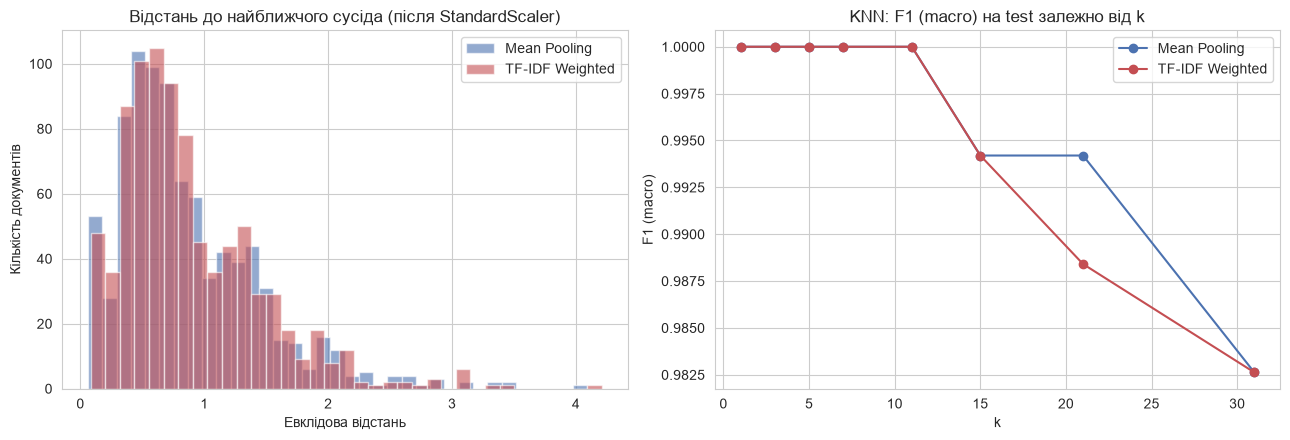

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for aggregation, color in zip(AGGREGATIONS, ['#4C72B0', '#C44E52']):
    scaled_matrix = StandardScaler().fit_transform(X_all[aggregation])
    distances = euclidean_distances(scaled_matrix)
    np.fill_diagonal(distances, np.inf)
    axes[0].hist(
        distances.min(axis=1), bins=35, alpha=0.6, color=color,
        edgecolor='white', label=aggregation,
    )
axes[0].set_title('Відстань до найближчого сусіда (після StandardScaler)')
axes[0].set_xlabel('Евклідова відстань')
axes[0].set_ylabel('Кількість документів')
axes[0].legend()

k_values = [1, 3, 5, 7, 11, 15, 21, 31]
for aggregation, color in zip(AGGREGATIONS, ['#4C72B0', '#C44E52']):
    scores = [
        f1_score(
            y_test,
            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
            .fit(X_train[aggregation], y_train)
            .predict(X_test[aggregation]),
            average='macro',
        )
        for k in k_values
    ]
    axes[1].plot(k_values, scores, marker='o', color=color, label=aggregation)
axes[1].set_title('KNN: F1 (macro) на test залежно від k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('F1 (macro)')
axes[1].legend()
plt.tight_layout()
plt.show()


**Висновки щодо геометрії:**
- **Простір визначають шаблони:** silhouette за шаблоном становить 0.78, за доменом 0.25, а за класом лише 0.07 для обох методів. Косинусна відстань всередині класу (0.161) майже дорівнює відстані між класами (0.164).
- **TF-IDF майже не змінює вектори:** косинус між Mean- і TF-IDF-представленням одного документа в середньому дорівнює 0.9998, відносний зсув становить 2.2%. Кількість компонент PCA на 90% дисперсії однакова (8), що теж вказує на низьку внутрішню розмірність.
- **Чистота 5-NN за класом** становить 0.998, бо найближчі сусіди — це документи того самого шаблону.
- **Відносний контраст** зменшується з 50.1 до 43.0: зважування трохи стискає різницю між близькими й далекими сусідами. Цього недостатньо, щоб вплинути на якість KNN: на правому графіку обидві криві лишаються близькими, а F1 = 1.000 тримається до $k = 11$. Якість знижується лише при більших $k$, коли сусіди вже виходять за межі острівця (шаблон містить у середньому близько 23 документи, а в train менше).


### 6.3. Лінгвістична інтерпретація

Для кожного слова рахуємо середнє TF-IDF у класах (лише train) і дивимось на різницю. Самі лише найвищі TF-IDF часто дають слова, типові для обох класів, тому показуємо також різницю між класами, частку документів кожного класу зі словом і символьні n-грами.


In [22]:
tfidf_words = fit_tfidf(train_df['tokens'].tolist())
matrix_words = tfidf_words.transform(train_df['tokens'].tolist())
vocabulary = tfidf_words.get_feature_names_out()
is_ai = y_train == 1


def class_profile(matrix, names: np.ndarray, mask: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame({
        'tfidf_ai': np.asarray(matrix[mask].mean(axis=0)).ravel(),
        'tfidf_human': np.asarray(matrix[~mask].mean(axis=0)).ravel(),
        'docs_ai_%': 100 * np.asarray((matrix[mask] > 0).mean(axis=0)).ravel(),
        'docs_human_%': 100 * np.asarray((matrix[~mask] > 0).mean(axis=0)).ravel(),
    }, index=names).assign(diff=lambda t: t['tfidf_ai'] - t['tfidf_human'])


word_profile = class_profile(matrix_words, vocabulary, is_ai)
print('TOP-15 слів за середнім TF-IDF у класі AI:')
display(word_profile.sort_values('tfidf_ai', ascending=False).head(15).round(3))
print('TOP-15 слів, найбільш зміщених до AI:')
display(word_profile.sort_values('diff', ascending=False).head(15).round(3))
print('TOP-15 слів, найбільш зміщених до Human:')
display(word_profile.sort_values('diff').head(15).round(3))

char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, norm=None)
matrix_chars = char_vectorizer.fit_transform(train_df['tokens'].str.join(' '))
char_profile = class_profile(matrix_chars, char_vectorizer.get_feature_names_out(), is_ai)
print('TOP-15 символьних n-грам, найбільш зміщених до AI:')
display(char_profile.sort_values('diff', ascending=False).head(15).round(3))


TOP-15 слів за середнім TF-IDF у класі AI:


,tfidf_ai,tfidf_human,docs_ai_%,docs_human_%,diff
challenge,0.804,0.417,31.068,16.667,0.388
framework,0.698,0.196,15.534,5.990,0.502
research,0.609,0.265,19.741,8.594,0.345
think,0.605,0.000,6.796,0.000,0.605
underscore,0.601,0.000,16.828,0.000,0.601
development,0.601,0.000,16.828,0.000,0.601
conversation,0.592,0.151,18.447,4.687,0.442
study,0.587,0.339,20.712,11.979,0.247
datum,0.586,0.286,19.417,9.375,0.300
expert,0.576,0.000,15.858,0.000,0.576


TOP-15 слів, найбільш зміщених до AI:


,tfidf_ai,tfidf_human,docs_ai_%,docs_human_%,diff
think,0.605,0.000,6.796,0.00,0.605
underscore,0.601,0.000,16.828,0.00,0.601
development,0.601,0.000,16.828,0.00,0.601
expert,0.576,0.000,15.858,0.00,0.576
solution,0.567,0.000,15.534,0.00,0.567
stakeholder,0.523,0.000,13.916,0.00,0.523
recommendation,0.514,0.000,13.592,0.00,0.514
framework,0.698,0.196,15.534,5.99,0.502
open,0.486,0.000,12.621,0.00,0.486
address,0.477,0.000,12.298,0.00,0.477


TOP-15 слів, найбільш зміщених до Human:


,tfidf_ai,tfidf_human,docs_ai_%,docs_human_%,diff
argue,0.000,0.616,0.000,19.010,-0.616
investigation,0.000,0.598,0.000,18.229,-0.598
official,0.170,0.712,6.149,25.781,-0.543
divide,0.063,0.561,1.942,16.927,-0.498
announcement,0.000,0.484,0.000,13.542,-0.484
supporter,0.000,0.484,0.000,13.542,-0.484
predictable,0.000,0.484,0.000,13.542,-0.484
speculation,0.000,0.484,0.000,13.542,-0.484
critic,0.000,0.484,0.000,13.542,-0.484
line,0.000,0.484,0.000,13.542,-0.484


TOP-15 символьних n-грам, найбільш зміщених до AI:


,tfidf_ai,tfidf_human,docs_ai_%,docs_human_%,diff
eco,1.321,0.139,35.599,5.208,1.182
end,1.241,0.063,38.511,2.344,1.179
ge,1.676,0.524,61.812,23.698,1.152
reco,1.101,0.000,31.392,0.000,1.101
reco,1.101,0.000,31.392,0.000,1.101
rec,1.215,0.145,36.246,5.469,1.071
ve,1.311,0.386,37.217,16.406,0.925
ent,2.141,1.259,60.841,70.312,0.882
po,1.376,0.499,45.631,22.917,0.877
ake,0.873,0.000,19.741,0.000,0.873


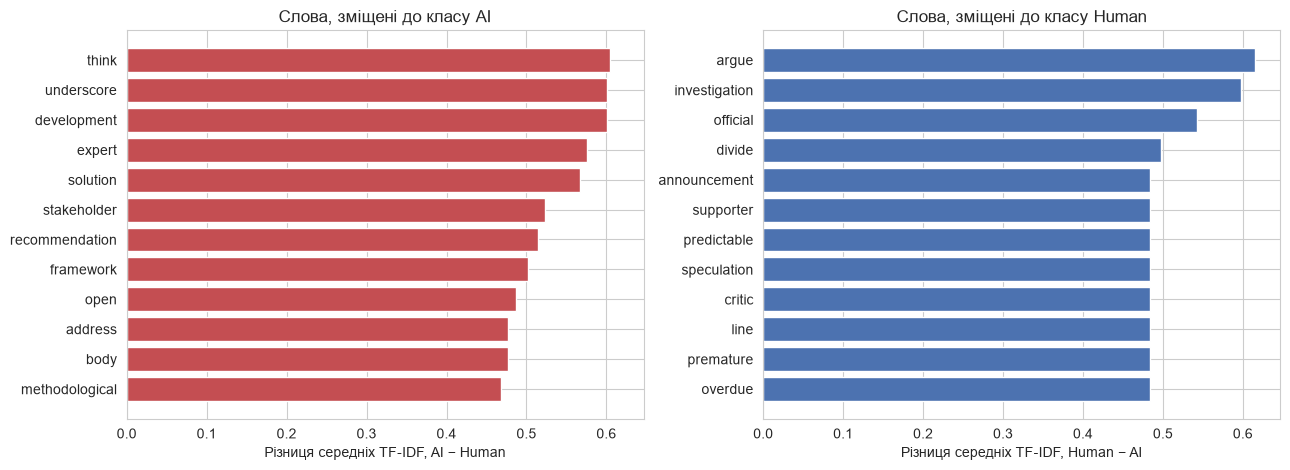

In [23]:
top_ai = word_profile.sort_values('diff', ascending=False).head(12)
top_human = word_profile.sort_values('diff').head(12)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
axes[0].barh(top_ai.index[::-1], top_ai['diff'][::-1], color=CLASS_COLORS['ai'])
axes[0].set_title('Слова, зміщені до класу AI')
axes[0].set_xlabel('Різниця середніх TF-IDF, AI − Human')
axes[1].barh(top_human.index[::-1], (-top_human['diff'])[::-1], color=CLASS_COLORS['human'])
axes[1].set_title('Слова, зміщені до класу Human')
axes[1].set_xlabel('Різниця середніх TF-IDF, Human − AI')
plt.tight_layout()
plt.show()


Чи справді ці слова є маркерами стилю? Перевіримо, скільки шаблонів класу AI стоїть за кожним словом. Якщо слово трапляється лише в одному-двох каркасах, його частота відображає будову датасету, а не звички мовних моделей.


In [24]:
ai_train = train_df[train_df['label'] == 'ai']
total_ai_templates = ai_train['template'].nunique()
marker_words = word_profile.sort_values('diff', ascending=False).head(15).index
marker_rows = []
for word in marker_words:
    containing = ai_train[ai_train['tokens'].map(lambda tokens: word in tokens)]
    marker_rows.append({
        'Слово': word,
        'Документів AI': len(containing),
        'Шаблонів AI зі словом': containing['template'].nunique(),
        'Документів Human': int(train_df[train_df['label'] == 'human']['tokens'].map(lambda tokens: word in tokens).sum()),
    })
marker_table = pd.DataFrame(marker_rows)
print('Усього шаблонів AI у train:', total_ai_templates)
display(marker_table)
print('Медіана шаблонів на слово:', marker_table['Шаблонів AI зі словом'].median())


Усього шаблонів AI у train: 18


,Слово,Документів AI,Шаблонів AI зі словом,Документів Human
0,think,21,1,0
1,underscore,52,3,0
2,development,52,3,0
3,expert,49,3,0
4,solution,48,3,0
5,stakeholder,43,3,0
6,recommendation,42,3,0
7,framework,48,3,23
8,open,39,2,0
9,address,38,3,0


Медіана шаблонів на слово: 3.0


**Інтерпретація.** Серед слів, зміщених до AI, багато лексики формального, «канцелярського» стилю: `underscore`, `stakeholder`, `framework`, `methodological`, `recommendation`, `solution`. На перший погляд це відповідає гіпотезі методички. Символьні n-грами (`reco`, `eco`) лише повторюють ті самі слова.

Але таблиця показує, що за кожним таким словом стоїть лише **1–3 шаблони зі 18** (медіана 3). Наприклад, `think` трапляється в 21 документі, і всі вони належать одному шаблону. Багато маркерів не мають жодного входження у класі Human просто тому, що шаблони класів не перетинаються. Симетрично, для Human виділяються `argue`, `official`, `speculation`, `premature`, які походять із фраз новинних шаблонів.

Отже, ці слова **не можна вважати доведеними маркерами** штучного тексту. Це відбитки конкретних шаблонів, що підтверджує падіння якості на нових шаблонах.


## Відповіді на дослідницькі питання

**1. Вплив агрегації.** TF-IDF зважування зміщує документний вектор до рідкісніших слів, тому теоретично мало б посилити специфічну лексику. На цих даних зміна мізерна: косинус між двома представленнями одного документа становить 0.9998, silhouette за класом змінюється з 0.066 до 0.068. Причин дві. По-перше, тексти короткі (близько 20–23 леми), слова майже не повторюються, тому вага визначається лише idf, а його діапазон вузький (приблизно від 2.5 до 6.9). Вилучення доданка $+1$ майже нічого не змінює. По-друге, усереднення FastText-векторів близьких за контекстом слів дає подібний результат незалежно від ваг. Покращення лінійної роздільності не виявлено: різниці статистично незначущі (p ≥ 0.27). **Гіпотеза методички на цьому датасеті не підтвердилась.**

**2. Порівняння класифікаторів.** За випадкового поділу найкращий для обох методів агрегації KNN (F1 = 0.9985 і 0.9990), за ним SVM (0.990 і 0.988) і LogReg (0.984 і 0.987). Це узгоджується з природою даних: кластер кожного шаблону компактний, а острівці класів перемежовуються, тому межа між класами нелінійна й кусково-складна. Локальний метод тут має перевагу, хоча LogReg теж працює добре, бо в 100-вимірному просторі 38 малих кластерів майже завжди можна розділити гіперплощиною. На нових шаблонах перевага KNN зникає (F1 ≈ 0.44), і достовірно кращого класифікатора немає.

**3. Чутливість KNN.** Методичка припускає можливу деградацію KNN при TF-IDF зважуванні: неоднакові ваги підвищують дисперсію вектора, бо він залежить від меншої кількості слів, а у високій розмірності відстані до близьких і далеких сусідів зближуються («прокляття розмірності»). **У цій роботі деградації немає:** F1 становить 0.9985 для Mean і 0.9990 для TF-IDF, різниця незначуща (p = 0.65). Контраст відстаней справді падає з 50.1 до 43.0, тобто напрям ефекту очікуваний, але він замалий. Ефективна розмірність низька (8 компонент PCA пояснюють 90% дисперсії), а найближчі сусіди лежать у тому самому щільному кластері шаблону, тому «прокляття розмірності» майже не проявляється. Деяку перевагу Mean видно лише на $k = 21$, тобто на межі розміру кластера.

**4. Лінгвістична інтерпретація.** Найбільші середні TF-IDF у класі AI мають `challenge`, `framework`, `research`, `think`, `underscore`, `development`, а найбільш зміщені до AI — `think`, `underscore`, `development`, `expert`, `solution`, `stakeholder`. Серед n-грам виділяються `reco`, `eco`, `end`. Частина з них схожа на канцеляризми, проте кожне слово походить із 1–3 шаблонів зі 18. На шаблонах, відсутніх у навчанні, класифікатор, побудований на цих представленнях, не перевищує рівень вгадування. Тому інтерпретувати їх як «маркери» штучного тексту на підставі цього датасету не можна.

**5. Геометричний аналіз.** Класи **не утворюють** двох компактних кластерів. На t-SNE видно близько 38 окремих острівців, що відповідають шаблонам, які групуються за доменом. Це підтверджують числа: silhouette 0.78 за шаблоном, 0.25 за доменом, 0.07 за класом. Жоден метод не дає кращої кластеризації: за класом TF-IDF випереджає на 0.002 (0.068 проти 0.066), а за шаблоном програє на 0.005 (0.776 проти 0.782). Це в межах шуму.


## Загальний висновок

Реалізовано повний пайплайн: spaCy → FastText → Mean Pooling / TF-IDF Weighted Mean → SVM, LogReg, KNN. Щоб уникнути витоку даних, дублікати видалено до розбиття, а FastText, idf і scaler навчалися лише на train.

- За пайплайном методички якість майже ідеальна: F1 від 0.984 до 0.999 у крос-валідації.
- Гіпотезу про перевагу TF-IDF **не підтверджено**: різниці незначущі, а самі вектори майже збігаються (косинус 0.9998).
- Висока якість є артефактом датасету. Він складається з 38 шаблонів, що не перетинаються між класами. На невідомих шаблонах F1 падає до 0.44–0.50, а ROC-AUC до рівня вгадування.
- Практичний висновок: моделі, навченій на цьому датасеті, не можна довіряти як детектору текстів LLM. Для такої оцінки потрібні реальні тексти людей і моделей та поділ за джерелом або шаблоном.

**Відхилення від методички:** видалення дублікатів до поділу, поділ до навчання FastText і TF-IDF, `workers=1` для відтворюваності, `StandardScaler` перед класифікаторами, додаткова крос-валідація за шаблонами. Усі вони спрямовані на коректність оцінки.
